In [4]:
import numpy as np
import cupy as cp
import matplotlib.pyplot as plt

from acoustic3d_cpml_gpu import acoustic3d_cpml_gpu


# ---------------------
# model
# ---------------------

dx = 0.5

nx = ny = nz = 100

vp0 = 3000.0

vp = np.ones(
    (nx,ny,nz),
    dtype=np.float32
)*vp0


# ---------------------
# time
# ---------------------

dt = 1e-5

nt = 2000

f0 = 100.0


# ---------------------
# source
# ---------------------

source_xyz = (
    25.0,
    25.0,
    25.0
)


# ---------------------
# receiver
# ---------------------

receiver_xyz = np.array(
    [
        [25.0,25.0,25.0]
    ],
    dtype=np.float32
)


n_pml = 20

In [5]:
receiver_xyz

array([[25., 25., 25.]], dtype=float32)

In [6]:
seis_gpu, _, snapshot_steps = acoustic3d_cpml_gpu(
    vp=vp,
    dx=dx,
    dt=dt,
    nt=nt,
    f0=f0,

    snapshot_stride=1,

    source_xyz=source_xyz,

    receiver_xyz=receiver_xyz,

    n_pml=n_pml,

    save_wavefield=False,
)


fd = cp.asnumpy(
    seis_gpu[:,0]
)

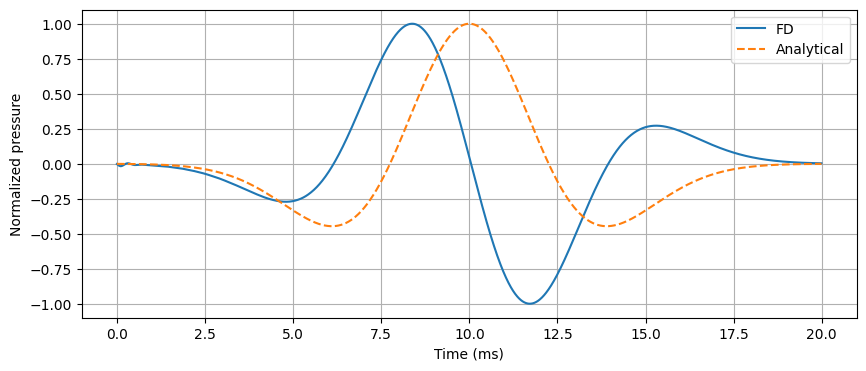

In [7]:
time = np.arange(nt)*dt


t0 = 1.0/f0

tau = time-t0


arg = np.pi*f0*tau


source = (
    1-2*arg**2
)*np.exp(
    -arg**2
)

r = np.linalg.norm(
    np.array(receiver_xyz[0])
    -
    np.array(source_xyz)
)

travel_time = r/vp0

tau = (
    time
    -
    travel_time
    -
    t0
)


arg = np.pi*f0*tau


exact = (
    1-2*arg**2
)*np.exp(
    -arg**2
)


fd_norm = fd/np.max(abs(fd))

exact_norm = exact/np.max(abs(exact))


plt.figure(figsize=(10,4))


plt.plot(
    time*1000,
    fd_norm,
    label="FD"
)


plt.plot(
    time*1000,
    exact_norm,
    "--",
    label="Analytical"
)


plt.xlabel("Time (ms)")
plt.ylabel("Normalized pressure")

plt.legend()

plt.grid()

plt.show()

In [8]:
t_fd = (
    np.argmax(abs(fd))
    *dt
)


t_exact = (
    travel_time+t0
)


print(
    "FD arrival:",
    t_fd*1000,
    "ms"
)


print(
    "Exact arrival:",
    t_exact*1000,
    "ms"
)


print(
    "error:",
    (t_fd-t_exact)*1000,
    "ms"
)

FD arrival: 11.72 ms
Exact arrival: 10.0 ms
error: 1.720000000000001 ms


In [9]:
error = (
    np.linalg.norm(
        fd_norm-exact_norm
    )
    /
    np.linalg.norm(
        exact_norm
    )
)


print(
    "L2 error=",
    error
)

L2 error= 1.4951172514529885


In [21]:
f0 = 200
time = cp.arange(nt, dtype=cp.float32) * cp.float32(dt)
# t0 = cp.float32(1.5 / f0)
t0 = cp.float32(1.5 / f0)
argument = (cp.float32(np.pi * f0) * (time - t0)) ** 2
source = (1.0 - 2.0 * argument) * cp.exp(-argument)

In [22]:
source.shape

(2000,)

In [23]:
source = cp.asnumpy(source)

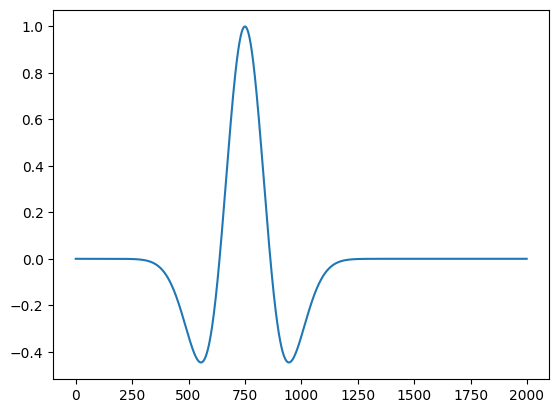

In [24]:
plt.plot(source)